# Lab 01 - Sentiment Analysis Using Traditional Machine Learning

### 1. Download and load dataset

In [8]:
import pandas as pd
import csv

amazon = pd.read_csv(r"C:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-01-Machine-Learning\data\sentiment+labelled+sentences\sentiment labelled sentences\amazon_cells_labelled.txt",
                       sep="\t", header=None, names=["text", "sentiment"], quoting=csv.QUOTE_NONE)

imdb = pd.read_csv(r"C:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-01-Machine-Learning\data\sentiment+labelled+sentences\sentiment labelled sentences\imdb_labelled.txt",
                       sep="\t", header=None, names=["text", "sentiment"], quoting=csv.QUOTE_NONE)

yelp = pd.read_csv(r"C:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-01-Machine-Learning\data\sentiment+labelled+sentences\sentiment labelled sentences\yelp_labelled.txt",
                       sep="\t", header=None, names=["text", "sentiment"], quoting=csv.QUOTE_NONE)


#identify the source of each dataset
amazon["source"]="Amazon"
imdb["source"]="IMDB"
yelp["source"]="Yelp"

df = pd.concat([amazon, imdb, yelp], ignore_index=True)

df.head()


,text,sentiment,source
0,So there is no way for me to plug it in here i...,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more...,0,Amazon
4,The mic is great.,1,Amazon


There was a data loading issue where only 2743 data was loaded out of 3000. To fix this i have added "quoting=csv.QUOTE_NONE"

In [9]:
print(df.shape)
print(df.columns)



(3000, 3)
Index(['text', 'sentiment', 'source'], dtype='object')


### 2. Perform basic text preprocessing

In [10]:
print("Amazon:", len(amazon))
print("IMDb:", len(imdb))
print("Yelp:", len(yelp))
print("Total:", len(amazon) + len(imdb) + len(yelp))

Amazon: 1000
IMDb: 1000
Yelp: 1000
Total: 3000


In [11]:

import re

#rename column 
df = df.rename(columns={"text": "review"})

#Check and remove if there is any incomplete rows, check label values
df = df.dropna(subset=["review", "sentiment"]).copy()
df["sentiment"]=pd.to_numeric(df["sentiment"], errors="coerce")
df=df[df["sentiment"].isin([0,1])].copy()
df["sentiment"]=df["sentiment"].astype(int)


def clean_txt(text):
    #convert to lowercase
    text=str(text).lower()

    #remove punctuations and symbols
    text=re.sub(r"[^a-z0-9\s]", " ", text)

    #remove extra whitespace
    text=re.sub(r"\s+", " ", text)

    return text.strip()

df["clean_txt"]=df["review"].apply(clean_txt)
df=df[df["clean_txt"] != ""].copy()

print("Original and Cleaned text:")
display(df[["review", "clean_txt"]].head(10))

print("Missing values after cleaning:")
print(df[["review", "sentiment", "clean_txt"]].isna().sum())
print("Exact duplicate cleaned reviews:", df["clean_txt"].duplicated().sum())

Original and Cleaned text:


,review,clean_txt
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


Missing values after cleaning:
review       0
sentiment    0
clean_txt    0
dtype: int64
Exact duplicate cleaned reviews: 28


Extra cleaning part - remove duplicates

In [12]:
starting_rows= len(df)
label_counts= df.groupby("clean_txt")["sentiment"].nunique()
conflicting_texts= set(label_counts[label_counts>1].index)

if conflicting_texts:
    df = df[~df["clean_txt"].isin(conflicting_texts)].copy()

df= df.drop_duplicates(subset=["clean_txt"]).reset_index(drop=True)

print("Rows befor duplicate checks:", starting_rows)
print("Conflicting cleaned texts excluded:", len(conflicting_texts))
print("Rows after duplicate checks:", len(df))

Rows befor duplicate checks: 3000
Conflicting cleaned texts excluded: 0
Rows after duplicate checks: 2972


### 3. Explore text data

Class distribution (0 = Negative, 1 = Positive):
sentiment
0    1486
1    1486
Name: count, dtype: int64
Distribution across review sources:


Sentiment,0,1
Source,,
Amazon,494,489
IMDB,497,498
Yelp,495,499


Example positive reviews:


,review,clean_txt
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
4,The mic is great.,the mic is great
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
10,And the sound quality is great.,and the sound quality is great


Example negative reviews:


,review,clean_txt
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
8,"Needless to say, I wasted my money.",needless to say i wasted my money


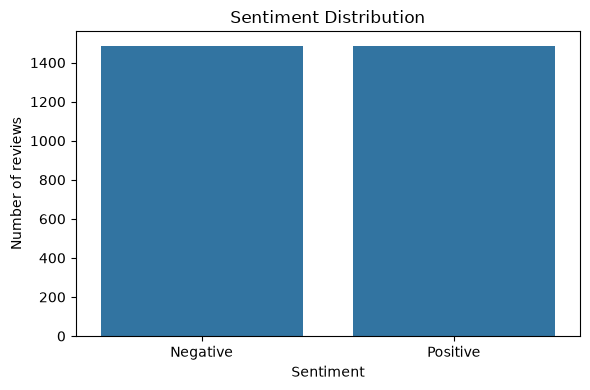

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Class distribution (0 = Negative, 1 = Positive):")
print(df["sentiment"].value_counts().sort_index())

print("Distribution across review sources:")
display(pd.crosstab(df["source"], df["sentiment"], rownames=["Source"], colnames=["Sentiment"]))

print("Example positive reviews:")
display(df.loc[df["sentiment"] == 1, ["review", "clean_txt"]].head(5))

print("Example negative reviews:")
display(df.loc[df["sentiment"] == 0, ["review", "clean_txt"]].head(5))

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="sentiment", order=[0,1], color="tab:blue")
plt.xticks([0,1], ["Negative", "Positive"])
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.title("Sentiment Distribution")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sentiment_distribution.png", dpi=150)
plt.show()

Common words in positive reviews: [('great', 191), ('good', 177), ('film', 105), ('movie', 86), ('phone', 83), ('best', 63), ('food', 60), ('place', 57), ('like', 56), ('not', 56), ('really', 56), ('love', 55)]
Common words in negative reviews: [('not', 246), ('bad', 100), ('movie', 96), ('phone', 79), ('like', 68), ('just', 66), ('food', 65), ('time', 62), ('don', 62), ('film', 58), ('place', 55), ('good', 53)]


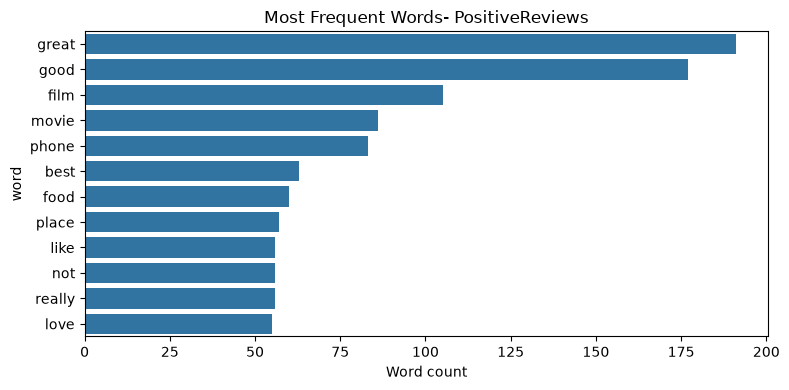

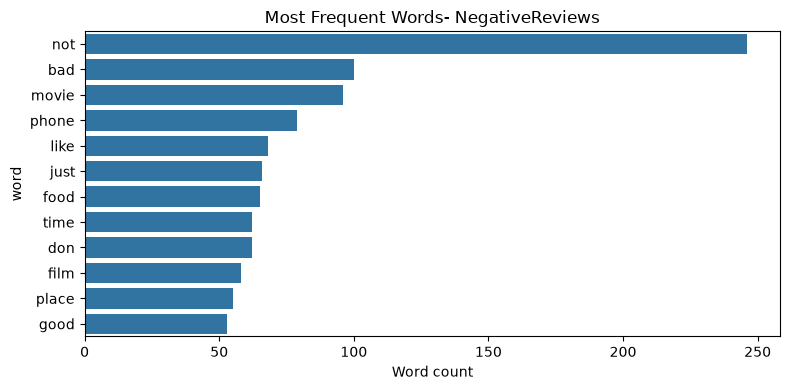

In [14]:
#stop words are ignored only for frequencyb plots
from collections import Counter as FreqDist
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

frequency_stopwords= set(ENGLISH_STOP_WORDS)-{"not", "no", "nor"}

def top_words(label, n=12):
    sentences= df.loc[df["sentiment"]==label, "clean_txt"]
    words= " ".join(sentences).split()
    words= [w for w in words if len(w)>2 and w not in frequency_stopwords]
    return FreqDist(words).most_common(n)

positive_words= top_words(1)
negative_words= top_words(0)
print("Common words in positive reviews:", positive_words)
print("Common words in negative reviews:", negative_words)

for label_name, pairs, filename in [
    ("Positive", positive_words, "top_words_positive.png"),
    ("Negative", negative_words, "top_words_negative.png")

]:
    words= [w for w, count in pairs]
    counts= [count for w, count in pairs]
    plt.figure(figsize=(8,4))
    sns.barplot(x=counts, y=words, color="tab:blue")
    plt.title(f"Most Frequent Words- {label_name}Reviews")
    plt.xlabel("Word count")
    plt.ylabel("word")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR/filename, dpi=150)
    plt.show()


### Exploratory Data Analysis – Observations


**Sentiment Distribution**

After removing duplicate cleaned reviews, the dataset contained **2,972 reviews**, consisting of:

- Negative reviews (0): 1,486
- Positive reviews (1): 1,486

The dataset is perfectly balanced between positive and negative sentiment, which is useful for evaluating the classification model without one class dominating the dataset.

The reviews originated from Amazon (983), IMDb (995), and Yelp (994).

**Frequently Occurring Words**

After excluding common English stop words for the frequency analysis, the following patterns were observed:

| Positive Reviews | Frequency | Negative Reviews | Frequency |
|---|---:|---|---:|
| great | 191 | not | 246 |
| good | 177 | bad | 100 |
| film | 105 | movie | 96 |
| movie | 86 | phone | 79 |
| phone | 83 | like | 68 |

Words such as **"great", "good", and "love"** frequently appeared in positive reviews, whereas **"not", "bad", and "don"** were common in negative reviews.

An interesting observation was that words such as **"movie", "phone", and "food"** appeared frequently in both sentiment classes. These words describe the topic of a review rather than directly expressing positive or negative opinions.

The word "good" also occurred in negative reviews, demonstrating that the sentiment of a sentence cannot always be determined from individual words alone.

The frequency analysis preserved important negation words such as "not", "no", and "nor" instead of removing them as stop words. This helped reveal the importance of negation in negative reviews.

**Conclusion:** Exploratory data analysis revealed useful differences in word usage between positive and negative reviews, while also highlighting the importance of context in sentiment analysis.



### 4. Split the dataset

In [15]:

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test= train_test_split(
    df["clean_txt"], df["sentiment"],
    test_size=0.20, random_state=42, stratify=df["sentiment"]
)

print("Training examples:", len(x_train))
print("Test examples:", len(x_test))
print("Training sentiment proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

Training examples: 2377
Test examples: 595
Training sentiment proportions:
sentiment
0    0.5
1    0.5
Name: proportion, dtype: float64



### Dataset Splitting – Explanation and Observations

The cleaned dataset was divided into **training and testing sets** using the `train_test_split()` function from Scikit-learn.

The following configuration was used:

| Parameter | Value |
|---|---|
| Total reviews | 2,972 |
| Training percentage | 80% |
| Testing percentage | 20% |
| Training samples | 2,377 |
| Testing samples | 595 |
| Random state | 42 |
| Stratification | Sentiment labels |

The training dataset was used to learn patterns associated with positive and negative sentiment, while the testing dataset was kept separate to evaluate the model's performance on unseen reviews.

The parameter `random_state=42` was used to make the data split reproducible, meaning the same split can be generated when the code is run again with the same dataset.

The parameter `stratify=df["sentiment"]` was used to preserve approximately equal proportions of positive and negative reviews in both subsets.

**Observation:** The training set maintained a 50% positive and 50% negative sentiment distribution, ensuring that the model received balanced training examples.

**Conclusion:** Separating the dataset before feature extraction and model training helps provide a more reliable evaluation of the model's ability to classify previously unseen reviews.


### 5. Create Bag-of-Words(BoW) Features

In [16]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer= CountVectorizer()
x_train_bow= vectorizer.fit_transform(x_train)
x_test_bow= vectorizer.transform(x_test)

print("Training BoW matrix shape:", x_train_bow.shape)
print("Test BoW matrix shape:", x_test_bow.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Example vocabulary terms:", vectorizer.get_feature_names_out()[:20])

Training BoW matrix shape: (2377, 4530)
Test BoW matrix shape: (595, 4530)
Vocabulary size: 4530
Example vocabulary terms: ['00' '10' '100' '11' '12' '13' '15' '15g' '15pm' '17' '18' '18th' '1928'
 '1947' '1948' '1949' '1973' '1979' '1998' '20']



###  Bag-of-Words Feature Extraction – Explanation and Observations

Machine learning algorithms require numerical inputs, so the cleaned text reviews were converted into numerical features using the **Bag-of-Words (BoW)** technique.

The `CountVectorizer` class from Scikit-learn was used to represent each review as a vector of word frequencies.

**Feature Extraction Results**

| Description | Result |
|---|---|
| Training BoW matrix | (2377, 4530) |
| Testing BoW matrix | (595, 4530) |
| Vocabulary size | 4,530 unique terms |

Each row represents a review, and each column corresponds to a vocabulary term. The numerical values indicate how frequently each term occurs in a particular review.

The vocabulary was learned using only the training data through `fit_transform()`. The testing data was then converted using `transform()` without learning a new vocabulary.

This approach prevents information from the testing dataset from influencing feature extraction during training.

**Observations**

Bag of Words provides a simple and effective method for converting unstructured text into numerical data. However, the resulting feature representation is sparse because each review contains only a small proportion of all vocabulary terms.

A limitation is that Bag of Words does not directly preserve word order or sentence structure. Consequently, it may struggle to distinguish phrases that contain similar words but express different meanings.

**Conclusion:** Bag-of-Words feature extraction successfully transformed the customer reviews into a numerical format suitable for machine learning classification, while demonstrating the limitations of frequency-based text representations.


### 6. Train a machine learning model

Logistic Regression

In [17]:
from sklearn.linear_model import LogisticRegression

model= LogisticRegression(max_iter=1000, random_state=42)
model.fit(x_train_bow, y_train)
print(":Logistic Regretion model trained")

:Logistic Regretion model trained



### Model Training – Explanation and Observations

A **Logistic Regression classifier** was selected to classify customer reviews as positive (1) or negative (0).

Logistic Regression is a supervised machine learning algorithm commonly used for binary classification tasks. It learns the relationship between numerical input features and target labels to estimate the probability of a particular class.

**Model Configuration**

| Parameter | Value |
|---|---|
| Algorithm | Logistic Regression |
| Feature representation | Bag of Words |
| Number of training samples | 2,377 |
| Number of input features | 4,530 |
| Maximum iterations | 1,000 |
| Random state | 42 |

The model was trained using the Bag-of-Words features and their corresponding sentiment labels.

The `max_iter=1000` parameter was selected to allow sufficient optimization iterations for model training.

**Observations**

The model training process completed successfully without a reported error.

During training, Logistic Regression learned weights associated with the vocabulary terms to identify patterns that help distinguish positive from negative sentiment.

**Conclusion:** Logistic Regression was successfully trained using the numerical features extracted from customer reviews. The trained model could then be evaluated using the separate testing dataset.


### 7. Evaluate model performance

Evaluation Metrics:
accuracy  : 0.8303
precision : 0.8333
recall    : 0.8249
f1_score  : 0.8291
Classification Report:
              precision    recall  f1-score   support

    Negative       0.83      0.84      0.83       298
    Positive       0.83      0.82      0.83       297

    accuracy                           0.83       595
   macro avg       0.83      0.83      0.83       595
weighted avg       0.83      0.83      0.83       595



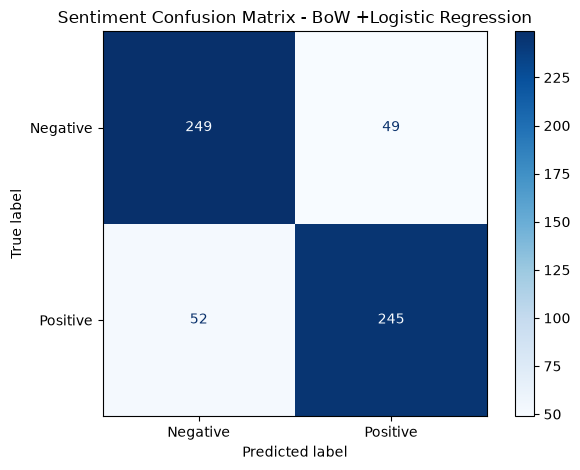

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

y_pred= model.predict(x_test_bow)
metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1_score": f1_score(y_test, y_pred, zero_division=0),
}

print("Evaluation Metrics:")
for name, value in metrics.items():
    print(f"{name:10s}: {value:.4f}")
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

pd.DataFrame([metrics]).to_csv(RESULTS_DIR/"evaluation_metrics.csv", index=False)

import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)
plt.title("Sentiment Confusion Matrix - BoW +Logistic Regression")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150)
plt.show()


Inspect actual misclassified reviews


In [20]:
# Find incorrectly classified reviews
error_df = pd.DataFrame({
    "review": df.loc[x_test.index, "review"].values,
    "actual": y_test.values,
    "predicted": y_pred
})

# Keep incorrect predictions only
mistakes = error_df[
    error_df["actual"] != error_df["predicted"]
]

print("Number of incorrect predictions:", len(mistakes))

# Display 10 examples
display(mistakes.head(10))

Number of incorrect predictions: 101


,review,actual,predicted
0,This is an unbelievable BARGAIN!,1,0
5,"Predictable, but not a bad watch.",1,0
14,Don't be afraid of subtitles........ its worth...,1,0
29,Very satisifed with that.,1,0
37,This is one of the better buffets that I have ...,1,0
39,Not too screamy not to masculine but just righ...,1,0
47,My only problem is I thought the actor playing...,0,1
53,"Small, sleek, impressive looking, practical se...",1,0
61,"However-the riingtones are not the best, and n...",0,1
62,"I've had no trouble accessing the Internet, do...",1,0



### Model Evaluation – Results and Interpretation

Four evaluation metrics were calculated: accuracy, precision, recall, and F1-score.


**Interpretation of Evaluation Metrics**

- **Accuracy (83.03%):** The model correctly classified approximately 83% of all reviews in the testing dataset.
- **Precision (83.33%):** Approximately 83% of reviews predicted as positive were actually positive.
- **Recall (82.49%):** The model successfully identified approximately 82% of the actual positive reviews.
- **F1-score (82.91%):** The model achieved a reasonable balance between precision and recall.

The relatively similar precision and recall values indicate that the classifier did not strongly favour one metric over the other.

**Confusion Matrix Analysis**


- **True Negatives (249):** Negative reviews correctly predicted as negative.
- **True Positives (245):** Positive reviews correctly predicted as positive.
- **False Positives (49):** Negative reviews incorrectly predicted as positive.
- **False Negatives (52):** Positive reviews incorrectly predicted as negative.

Overall, the model made **494 correct predictions and 101 incorrect predictions** out of 595 test reviews.

The number of false positives and false negatives was relatively similar. However, these errors show that the model cannot correctly interpret every review.

Some sentiment expressions may be difficult to classify using individual word frequencies, particularly sentences involving negation, ambiguous wording, or mixed opinions. Further analysis of individual misclassified reviews would be needed to confirm which of these patterns contributed to the observed errors.

**Conclusion:** The model achieved 83.03% accuracy on the held-out test dataset, demonstrating that Bag of Words combined with Logistic Regression can provide a useful baseline for binary sentiment classification. However, the remaining classification errors indicate opportunities for improvement.




### 8. Test the model with new sentences

In [21]:
new_sentences = [
    "I absolutely loved this movie!",
    "The food was cold and disappointing.",
    "This product works perfectly.",
    "I would not recommend it to anyone.",
]
new_clean = [clean_txt(sentence) for sentence in new_sentences]
new_vectors = vectorizer.transform(new_clean)
new_labels = model.predict(new_vectors)

predictions = pd.DataFrame({
    "sentence": new_sentences,
    "clean_text": new_clean,
    "predicted_label": new_labels,
    "predicted_sentiment": ["Positive" if value == 1 else "Negative" for value in new_labels],
})
display(predictions)
predictions.to_csv(RESULTS_DIR / "new_sentence_predictions.csv", index=False)

,sentence,clean_text,predicted_label,predicted_sentiment
0,I absolutely loved this movie!,i absolutely loved this movie,1,Positive
1,The food was cold and disappointing.,the food was cold and disappointing,0,Negative
2,This product works perfectly.,this product works perfectly,1,Positive
3,I would not recommend it to anyone.,i would not recommend it to anyone,0,Negative


**Observations**

The model correctly predicted the apparent sentiment of all four selected example sentences.

Positive expressions such as "loved" and "perfectly" were classified as positive, while negative expressions such as "cold and disappointing" were classified as negative.

An interesting observation was that the sentence **"I would not recommend it to anyone."** was correctly classified as negative.

Although Bag of Words does not preserve word order, the model was able to classify this example correctly using the learned word-frequency features.

However, correct predictions on four selected sentences do not guarantee that the model will perform equally well on all unseen reviews. More challenging examples and additional testing would be necessary to assess its robustness.

**Conclusion:** The model successfully performed sentiment predictions on the selected new sentences, demonstrating how a trained text classifier can be applied to previously unseen input data.

# Additional Experiments

Comparing NLP Techniques

### Objective

The objective of these additional experiments is to investigate whether different text representations and machine learning algorithms improve sentiment classification compared with the original Bag-of-Words and Logistic Regression baseline.

The experiments use the same training and testing data to support consistent comparisons.

### Experiment 1: TF-IDF + Logistic Regression

In [22]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create TF-IDF features
tfidf_vectorizer = TfidfVectorizer()

# Fit only on training data
x_train_tfidf = tfidf_vectorizer.fit_transform(x_train)
x_test_tfidf = tfidf_vectorizer.transform(x_test)

# Train Logistic Regression
tfidf_model = LogisticRegression(max_iter=1000, random_state=42)
tfidf_model.fit(x_train_tfidf, y_train)

# Predict test reviews
tfidf_pred = tfidf_model.predict(x_test_tfidf)

print("TF-IDF Accuracy:",
      round(accuracy_score(y_test, tfidf_pred), 4))

print("TF-IDF F1-score:",
      round(f1_score(y_test, tfidf_pred), 4))


TF-IDF Accuracy: 0.8286
TF-IDF F1-score: 0.8289


### Experiment 2: Bag of Words with Bigrams

In [23]:

from sklearn.feature_extraction.text import CountVectorizer

# Include single words and two-word combinations
bigram_vectorizer = CountVectorizer(ngram_range=(1, 2))

# Create training and testing features
x_train_bigram = bigram_vectorizer.fit_transform(x_train)
x_test_bigram = bigram_vectorizer.transform(x_test)

# Train Logistic Regression
bigram_model = LogisticRegression(max_iter=1000, random_state=42)
bigram_model.fit(x_train_bigram, y_train)

# Predict test reviews
bigram_pred = bigram_model.predict(x_test_bigram)

print("Unigram + Bigram Accuracy:",
      round(accuracy_score(y_test, bigram_pred), 4))

print("Unigram + Bigram F1-score:",
      round(f1_score(y_test, bigram_pred), 4))

print("Vocabulary size:", len(bigram_vectorizer.vocabulary_))


Unigram + Bigram Accuracy: 0.8353
Unigram + Bigram F1-score: 0.8356
Vocabulary size: 21352


### Experiment 3: Support Vector Machine (SVM)

In [24]:

from sklearn.svm import LinearSVC

# Create and train SVM
svm_model = LinearSVC(random_state=42, max_iter=5000)
svm_model.fit(x_train_bow, y_train)

# Predict using the original BoW test features
svm_pred = svm_model.predict(x_test_bow)

print("SVM Accuracy:",
      round(accuracy_score(y_test, svm_pred), 4))

print("SVM F1-score:",
      round(f1_score(y_test, svm_pred), 4))


SVM Accuracy: 0.8168
SVM F1-score: 0.8186


### Comparison of all 4 models

In [25]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# Collect predictions from all models
experiments = {
    "BoW + Logistic Regression": y_pred,
    "TF-IDF + Logistic Regression": tfidf_pred,
    "BoW + Bigrams + Logistic Regression": bigram_pred,
    "BoW + Linear SVM": svm_pred
}

# Calculate metrics
comparison = []

for name, predictions in experiments.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions)
    })

# Create comparison table
comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

# Save results
comparison_df.to_csv(
    RESULTS_DIR / "optional_experiment_comparison.csv",
    index=False
)


,Model,Accuracy,Precision,Recall,F1-score
0,BoW + Logistic Regression,0.8303,0.8333,0.8249,0.8291
1,TF-IDF + Logistic Regression,0.8286,0.8261,0.8316,0.8289
2,BoW + Bigrams + Logistic Regression,0.8353,0.8328,0.8384,0.8356
3,BoW + Linear SVM,0.8168,0.8092,0.8283,0.8186


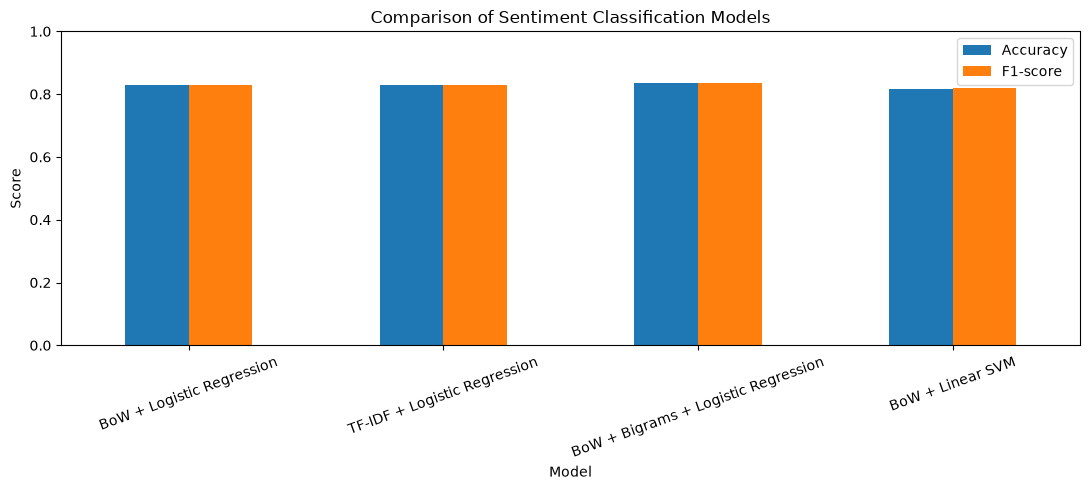

In [26]:

# Compare accuracy and F1-score
comparison_df.plot(
    x="Model",
    y=["Accuracy", "F1-score"],
    kind="bar",
    figsize=(11, 5),
    rot=20
)

plt.title("Comparison of Sentiment Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "model_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()



## 10. Conclusion and Reflection

#### 10.1 Overall Conclusion

In this laboratory, I successfully implemented a sentiment analysis model using traditional Natural Language Processing (NLP) and machine learning techniques.

The practical involved loading labelled customer reviews from Amazon, IMDb, and Yelp, performing text preprocessing, exploring the dataset, extracting Bag-of-Words features, training a Logistic Regression classifier, and evaluating its performance.

The final dataset contained **2,972 reviews** after duplicate removal, with an equal distribution of positive and negative sentiment labels.

The model achieved an **accuracy of 83.03%**, precision of **83.33%**, recall of **82.49%**, and F1-score of **82.91%** on the testing dataset.

These results demonstrate that traditional machine learning techniques can effectively identify sentiment patterns in customer reviews.

#### 10.2 Key Findings

Several important findings were identified during this practical.

**Text Preprocessing**

Converting reviews to lowercase, removing unnecessary punctuation, and eliminating extra whitespace produced more consistent text representations.

For example:

- Original: "Good case, Excellent value."
- Cleaned: "good case excellent value"

This demonstrated how text preprocessing reduces unnecessary variation before feature extraction.

**Word Frequency Analysis**

Positive reviews frequently contained words such as "great", "good", and "love", while negative reviews commonly contained "not" and "bad".

However, words such as "movie", "phone", and "food" appeared in both sentiment classes, demonstrating that word frequency alone does not fully capture sentiment.

**Model Performance**

The classifier correctly predicted 494 out of 595 test reviews.

The confusion matrix showed 49 false positives and 52 false negatives, indicating that the model made errors in both sentiment classes.

**New Sentence Testing**

The trained model successfully classified all four selected test sentences according to their apparent sentiment, demonstrating its ability to process new text inputs.

#### 10.3 Challenges Encountered

One challenge encountered during the practical was correctly loading the dataset.

Initially, fewer than the expected 3,000 reviews were loaded because of the handling of quotation marks in the text files.

This issue was resolved by using `quoting=csv.QUOTE_NONE` when reading the dataset with Pandas.

After the correction, all 3,000 original reviews were successfully loaded, consisting of 1,000 reviews from each source.

I also identified duplicate cleaned reviews during preprocessing and used duplicate-removal procedures before splitting the dataset.

These experiences highlighted the importance of checking dataset completeness, data quality, and preprocessing results before training a machine learning model.

#### 10.4 Limitations of the Approach

Although the model achieved reasonable classification performance, several limitations were identified.

**Loss of Word Order**

Bag of Words represents reviews using word frequencies without directly preserving the order of words.

For example, phrases such as "good" and "not good" may be difficult to distinguish reliably using individual-word features.

**Limited Contextual Understanding**

The model does not directly understand the relationships between words, which may affect predictions involving sarcasm, mixed opinions, or ambiguous expressions.

**Information Loss During Cleaning**

Removing punctuation can sometimes change the representation of contractions and other meaningful text patterns.

**Classification Errors**

The model incorrectly classified 101 test reviews, showing that the selected features and classifier were unable to capture every sentiment pattern.

These limitations highlight why more advanced text representations may be useful for improving sentiment classification.

#### 10.5 Possible Future Improvements

Based on the practical results, the following improvements could be investigated in future experiments:

- Compare Bag of Words with TF-IDF to examine whether term weighting improves classification performance.
- Use bigrams to represent combinations of two consecutive words, such as "not good".
- Compare Logistic Regression with other classification algorithms, such as Support Vector Machines.
- Examine misclassified reviews to identify common error patterns.
- Explore word embeddings or contextual language representations to capture more semantic information.

These are suggested future improvements and were not evaluated in the current experiment.

#### 10.6 Learning Outcomes

Through this laboratory, I gained practical experience in:

1. Loading and combining text datasets using Pandas.
2. Cleaning and preparing unstructured text using Python and regular expressions.
3. Exploring sentiment distributions and identifying frequently occurring words.
4. Converting text into numerical features using Bag of Words.
5. Dividing datasets into training and testing sets.
6. Training a Logistic Regression classification model.
7. Evaluating classification performance using accuracy, precision, recall, F1-score, and a confusion matrix.
8. Applying a trained model to new text inputs.
9. Understanding the importance of data quality, reproducibility, and avoiding data leakage.
10. Recognising the strengths and limitations of traditional NLP approaches.

#### 10.7 Final Reflection

The most important lesson I learned from this practical was that the quality of text representation plays a significant role in machine learning performance.

Before completing this laboratory, my understanding of sentiment analysis was mainly theoretical. Implementing the complete process helped me understand how raw text is transformed into numerical features and how those features are used to train a classifier.

I also learned that achieving a reasonable accuracy score does not mean a model is perfect. Evaluating the confusion matrix and considering the limitations of Bag of Words provided a better understanding of the model's strengths and weaknesses.

Overall, this practical strengthened my knowledge of text preprocessing, feature extraction, supervised learning, and model evaluation. It also established an important foundation for understanding more advanced NLP techniques, including word embeddings and Transformer-based language models.
